In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/superstore.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (17024, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [5]:

# STEP 1: Explore Dataset Structure

print("Number of rows and columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Number of rows and columns:
(17024, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17024 entries, 0 to 17023
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         17024 non-null  object 
 1   Order ID       17024 non-null  object 
 2   Order Date     15412 non-null  object 
 3   Ship Date      15412 non-null  object 
 4   Ship Mode      15412 non-null  object 
 5   Customer ID    15412 non-null  object 
 6   Customer Name  15412 non-null  object 
 7   Segment        15412 non-null  object 
 8   Country        15412 non-null  object 
 9   City           15412 non-null  object 
 10  State          15412 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,17024,10002,Yes,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,17024,5016,CA-2018-100111,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,15412,1237,9/5/2017,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,15412,1335,12/6/2018,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,15412,5,Standard Class,9242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,15412,794,WB-21850,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,15412,794,William Brown,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,15412,4,Consumer,7954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,15412,2,United States,15411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,15412,532,New York City,1405,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

# STEP 3: Data Quality Check

print("Dataset Shape:", df.shape)

print("\nMissing Values (highest first):")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nNumerical Columns Summary:")
display(df.describe().T)

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (17024, 21)

Missing Values (highest first):
Postal Code      1633
Region           1613
Quantity         1613
Discount         1613
Profit           1613
Category         1613
Sales            1613
Product Name     1613
Sub-Category     1613
Product ID       1613
Order Date       1612
Ship Mode        1612
Ship Date        1612
City             1612
State            1612
Customer Name    1612
Customer ID      1612
Segment          1612
Country          1612
dtype: int64

Duplicate Rows: 6727

Data Types:
Row ID            object
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity         float64

,count,mean,std,min,25%,50%,75%,max
Postal Code,15391.0,55349.090749,32121.573241,6.715,23223.0000,59601.0000,90008.000,99301.000
Sales,15411.0,229.080868,615.015040,0.444,17.4400,54.9200,209.600,22638.480
Quantity,15411.0,3.785608,2.219021,1.000,2.0000,3.0000,5.000,14.000
Discount,15411.0,0.156062,0.206511,0.000,0.0000,0.2000,0.200,0.800
Profit,15411.0,29.381395,240.719537,-6599.978,1.7248,8.6352,29.495,8399.976



First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [7]:

# STEP 4: Missing Values Percentage

missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_report)

print("Total duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
Postal Code,1633,9.59
Ship Date,1612,9.47
Order Date,1612,9.47
Ship Mode,1612,9.47
Customer ID,1612,9.47
Segment,1612,9.47
Customer Name,1612,9.47
Country,1612,9.47
City,1612,9.47
State,1612,9.47


Total duplicate rows: 6727


In [8]:

# STEP 5: Inspect Rows with Many Missing Values

missing_per_row = df.isnull().sum(axis=1)

print("Rows with 5 or more missing values:",
      (missing_per_row >= 5).sum())

display(df.loc[missing_per_row >= 5].head(10))


Rows with 5 or more missing values: 1613


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:

# STEP 6: Investigate suspicious rows

print("Rows around the suspected problem:")
display(df.iloc[9988:10005])

print("\nLast 10 rows of the dataset:")
display(df.tail(10))

print("\nData types of important columns:")
print(df[["Row ID", "Order ID", "Sales", "Profit"]].dtypes)

print("\nNumber of rows with missing values:")
print(df.isnull().any(axis=1).sum())


Rows around the suspected problem:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9988,9989,CA-2018-163629,11/17/2018,11/21/2018,Standard Class,RA-19885,Ruben Ausman,Corporate,United States,Athens,...,30605.0,South,TEC-PH-10004006,Technology,Phones,Panasonic KX - TS880B Telephone,206.100,5.0,0.0,55.6470
9989,9990,CA-2015-110422,1/21/2015,1/23/2015,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3.0,0.2,4.1028
9990,9991,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2.0,0.0,15.6332
9991,9992,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2.0,0.2,19.3932
9992,9993,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4.0,0.0,13.3200
9993,9994,CA-2018-119914,5/4/2018,5/9/2018,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2.0,0.0,72.9480
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Last 10 rows of the dataset:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
17014,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17015,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17016,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17017,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17018,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17019,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17020,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17021,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17022,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17023,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Data types of important columns:
Row ID       object
Order ID     object
Sales       float64
Profit      float64
dtype: object

Number of rows with missing values:
1634


In [10]:

# STEP 7: Separate valid sales records

sales_df = df[
    df["Order Date"].notna() &
    df["Sales"].notna()
].copy()

# Convert columns to their appropriate data types
sales_df["Row ID"] = pd.to_numeric(
    sales_df["Row ID"], errors="coerce"
)

sales_df["Order Date"] = pd.to_datetime(
    sales_df["Order Date"], format="%m/%d/%Y", errors="coerce"
)

sales_df["Ship Date"] = pd.to_datetime(
    sales_df["Ship Date"], format="%m/%d/%Y", errors="coerce"
)

print("Original dataset shape:", df.shape)
print("Clean sales dataset shape:", sales_df.shape)

print("\nMissing values after separating sales records:")
print(sales_df.isnull().sum()[sales_df.isnull().sum() > 0])

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nFirst 5 sales records:")
display(sales_df.head())


Original dataset shape: (17024, 21)
Clean sales dataset shape: (15411, 21)

Missing values after separating sales records:
Postal Code    21
dtype: int64

Duplicate rows: 5417

First 5 sales records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [11]:

# STEP 8: Verify the actual sales records

print("Rows with Order Date:", df["Order Date"].notna().sum())
print("Rows with Sales:", df["Sales"].notna().sum())

valid_mask = df["Order Date"].notna() & df["Sales"].notna()
print("Rows with both Order Date and Sales:", valid_mask.sum())

print("\nRows around index 9990 to 10010:")
display(df.iloc[9990:10011])

print("\nLast 10 rows that have both Order Date and Sales:")
display(
    df.loc[valid_mask, ["Row ID", "Order ID", "Order Date", "Sales"]].tail(10)
)

print("\nUnique Row IDs:", df["Row ID"].nunique())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())


Rows with Order Date: 15412
Rows with Sales: 15411
Rows with both Order Date and Sales: 15411

Rows around index 9990 to 10010:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9990,9991,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2.0,0.0,15.6332
9991,9992,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2.0,0.2,19.3932
9992,9993,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4.0,0.0,13.3200
9993,9994,CA-2018-119914,5/4/2018,5/9/2018,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2.0,0.0,72.9480
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Last 10 rows that have both Order Date and Sales:


,Row ID,Order ID,Order Date,Sales
16208,9985,CA-2016-100251,5/17/2016,31.500
16209,9986,CA-2016-100251,5/17/2016,55.600
16210,9987,CA-2017-125794,9/29/2017,36.240
16211,9988,CA-2018-163629,11/17/2018,79.990
16212,9989,CA-2018-163629,11/17/2018,206.100
16213,9990,CA-2015-110422,1/21/2015,25.248
16214,9991,CA-2018-121258,2/26/2018,91.960
16215,9992,CA-2018-121258,2/26/2018,258.576
16216,9993,CA-2018-121258,2/26/2018,29.600
16217,9994,CA-2018-119914,5/4/2018,243.160



Unique Row IDs: 10002
Duplicate Row IDs: 7022


In [12]:

# STEP 9: Create the clean sales dataset

# Keep the original sales section before the extra People/Returns data
clean_df = df.iloc[:9994].copy()

# Convert data types
clean_df["Row ID"] = pd.to_numeric(
    clean_df["Row ID"], errors="coerce"
)

clean_df["Order Date"] = pd.to_datetime(
    clean_df["Order Date"], errors="coerce"
)

clean_df["Ship Date"] = pd.to_datetime(
    clean_df["Ship Date"], errors="coerce"
)

# Validate the cleaned dataset
print("Clean dataset shape:", clean_df.shape)
print("Unique Row IDs:", clean_df["Row ID"].nunique())
print("Duplicate Row IDs:", clean_df["Row ID"].duplicated().sum())
print("Duplicate full rows:", clean_df.duplicated().sum())

print("\nMissing values:")
print(clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

print("\nFirst 5 cleaned records:")
display(clean_df.head())


Clean dataset shape: (9994, 21)
Unique Row IDs: 9994
Duplicate Row IDs: 0
Duplicate full rows: 0

Missing values:
Postal Code    11
dtype: int64

First 5 cleaned records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


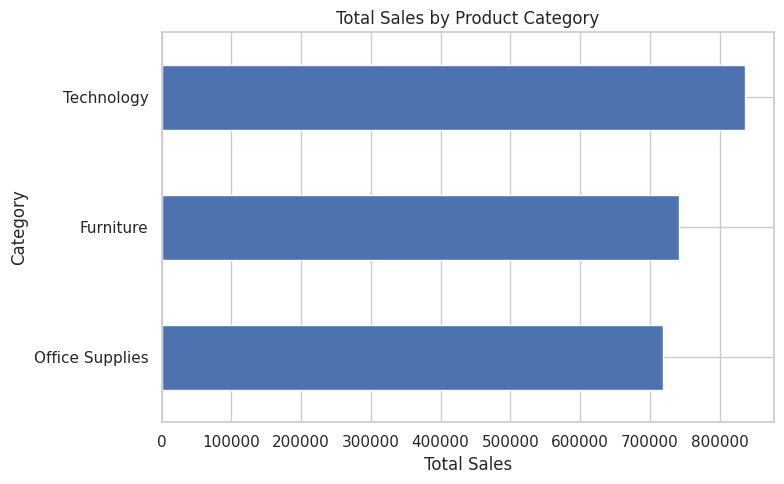

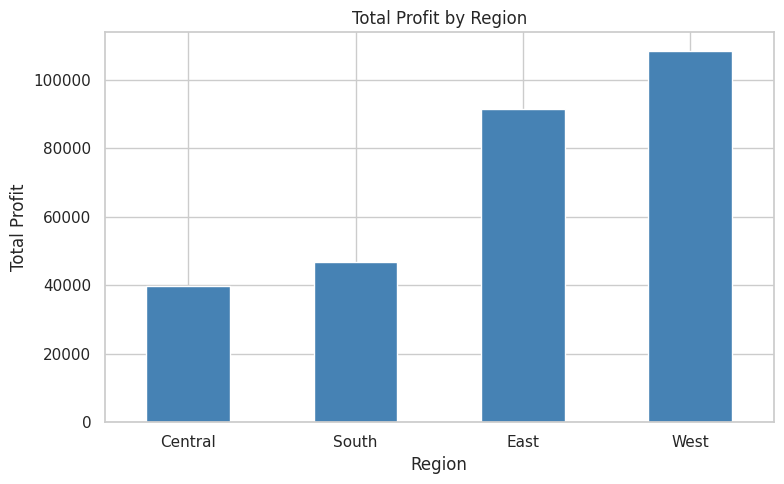

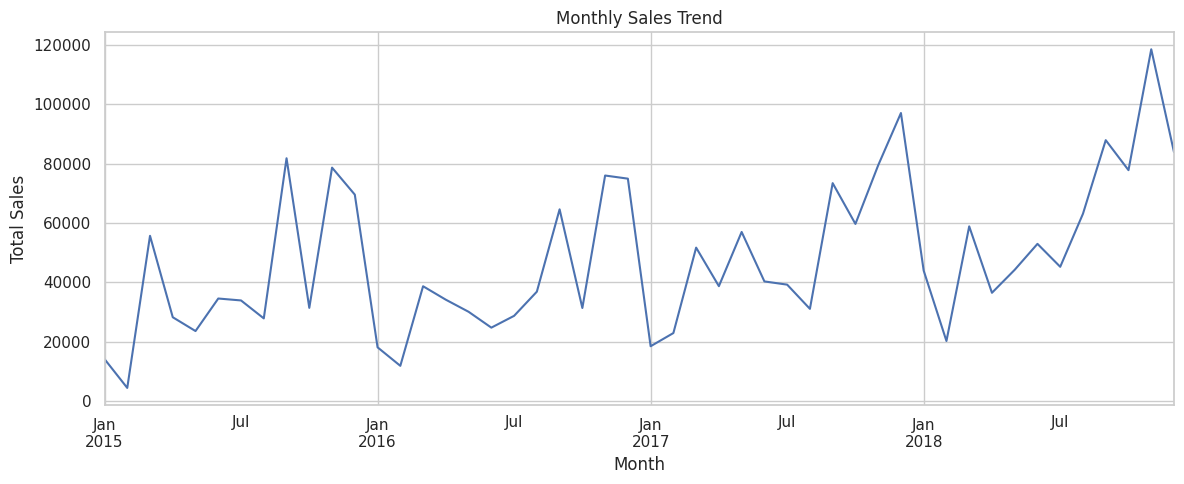

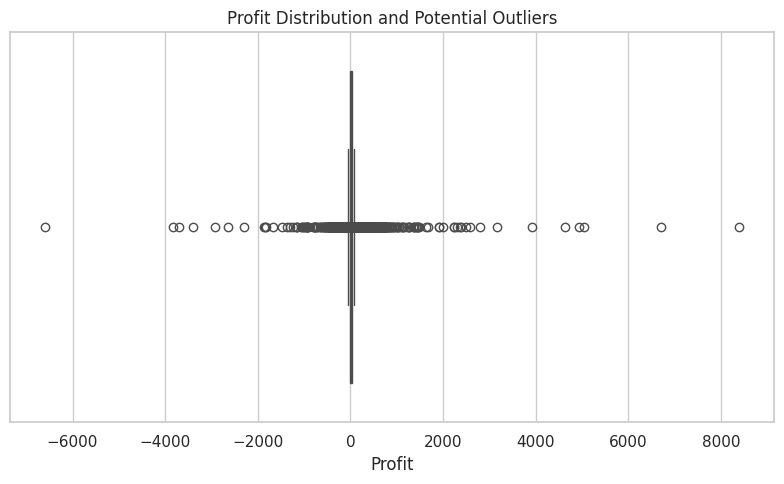

Sales by Category:


,Total Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


Profit by Region:


,Total Profit
Region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625


Negative-profit records: 1871


In [13]:

# STEP 11: Exploratory Data Analysis Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Sales by Category
category_sales = clean_df.groupby("Category")["Sales"].sum().sort_values()

plt.figure(figsize=(8, 5))
category_sales.plot(kind="barh")
plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# 2. Profit by Region
region_profit = clean_df.groupby("Region")["Profit"].sum().sort_values()

plt.figure(figsize=(8, 5))
region_profit.plot(kind="bar", color="steelblue")
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Monthly Sales Trend
monthly_sales = (
    clean_df.set_index("Order Date")["Sales"]
    .resample("ME").sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 4. Profit Distribution and Outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=clean_df["Profit"])
plt.title("Profit Distribution and Potential Outliers")
plt.xlabel("Profit")
plt.tight_layout()
plt.show()

# Summary tables
print("Sales by Category:")
display(category_sales.sort_values(ascending=False).to_frame("Total Sales"))

print("Profit by Region:")
display(region_profit.sort_values(ascending=False).to_frame("Total Profit"))

print("Negative-profit records:", (clean_df["Profit"] < 0).sum())


In [14]:

import pandas as pd
from scipy.stats import f_oneway, pearsonr

# Make sure dates and numerical columns are correctly formatted
clean_df["Sales"] = pd.to_numeric(clean_df["Sales"], errors="coerce")
clean_df["Profit"] = pd.to_numeric(clean_df["Profit"], errors="coerce")

# Hypothesis 1: Does average profit differ across regions?
regional_profits = [
    group["Profit"].dropna().values
    for _, group in clean_df.groupby("Region")
]

f_stat, p_value = f_oneway(*regional_profits)

print("HYPOTHESIS TEST: Average Profit Across Regions")
print("H0: Average profit is equal across all regions.")
print("H1: At least one region has a different average profit.")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Significant difference found (reject H0).")
else:
    print("Result: No statistically significant difference found (fail to reject H0).")

# Hypothesis 2: Are Sales and Profit linearly correlated?
correlation_data = clean_df[["Sales", "Profit"]].dropna()
corr, corr_p = pearsonr(
    correlation_data["Sales"],
    correlation_data["Profit"]
)

print("\nCORRELATION: Sales vs Profit")
print(f"Pearson correlation: {corr:.4f}")
print(f"P-value: {corr_p:.6f}")

if corr_p < 0.05:
    print("The linear correlation is statistically significant.")
else:
    print("No statistically significant linear correlation was detected.")


HYPOTHESIS TEST: Average Profit Across Regions
H0: Average profit is equal across all regions.
H1: At least one region has a different average profit.
F-statistic: 2.6225
P-value: 0.048892
Result: Significant difference found (reject H0).

CORRELATION: Sales vs Profit
Pearson correlation: 0.4791
P-value: 0.000000
The linear correlation is statistically significant.


In [15]:

print("FINAL DATA QUALITY CHECK")
print("-" * 35)

print("Dataset shape:", clean_df.shape)
print("Duplicate full rows:", clean_df.duplicated().sum())
print("\nMissing values by column:")
print(clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

print("\nNegative profit records:", (clean_df["Profit"] < 0).sum())
print("Potential negative sales records:", (clean_df["Sales"] < 0).sum())

print("\nDate range:")
print("Start:", clean_df["Order Date"].min())
print("End:", clean_df["Order Date"].max())


FINAL DATA QUALITY CHECK
-----------------------------------
Dataset shape: (9994, 21)
Duplicate full rows: 0

Missing values by column:
Postal Code    11
dtype: int64

Negative profit records: 1871
Potential negative sales records: 0

Date range:
Start: 2015-01-03 00:00:00
End: 2018-12-30 00:00:00
